# AI-Powered Vehicle Sales Report Generator 

**Business Problem**

Vehicle sales data and dealer information are stored in separate datasets. 

The goal is to: 
- Clean and transform raw vehicle sales data
- Merge dealer information
- Analyze sales performance
- Generate business KPIs
- Create visualisations
- Produce an AI-Assisted sales report
- Validate AI-generated numbers 

## 1. Import Libraries 

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import re 

## 2. Load Both Datasets 

In [2]:
sales = pd.read_csv("vehicle_sales_raw.csv")
dealers = pd.read_csv("dealers_dim.csv")

**Quick insepection:**

In [3]:
sales.head()

,sale_id,sale_date,make,model,year,mileage_km,fuel_type,transmission,body_type,condition,colour,listing_price_zar,sale_price_zar,days_to_sell,finance_type,dealer_id
0,VS003483,10/12/2025,BMW,X3,2022.0,55100,Diesel,Manual,SUV,Fair,Grey,302000,"R274,000",21,Trade-in,D002
1,VS003866,12/01/2025,Toyota,Corolla Cross,2013.0,304900,Petrol,Manual,SUV,Excellent,White,118000,113000,15,Dealer Finance,D030
2,VS001861,2025-07-18,Toyota,Hilux,2022.0,98400,Diesel,automatic,Bakkie,Poor,White,289000,272500,41,Trade-in,D009
3,VS000542,2024-06-23,Volkswagen,Tiguan,2013.0,215200,Petrol,Man,SUV,Excellent,White,68000,"R67,000",5,Trade-in,D014
4,VS005209,2024-08-12,Toyota,Hilux,2026.0,300,Diesel,Manual,Bakkie,Fair,Black,450000,426000,36,Bank Finance,D007


In [4]:
dealers.head()

,dealer_id,dealer_name,province,dealer_type
0,D001,Natal Motor Group,Gauteng,Franchise
1,D002,Jozi Motor Group,Eastern Cape,Independent
2,D003,Table Bay Motor Group,Limpopo,Independent
3,D004,Natal Motor Group,Gauteng,Franchise
4,D005,Natal Motor Group,Gauteng,Independent


## 3. Data Understanding 

**For sales dataset:**

In [5]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 7110 entries, 0 to 7109
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sale_id            7110 non-null   str    
 1   sale_date          7110 non-null   str    
 2   make               7110 non-null   str    
 3   model              7110 non-null   str    
 4   year               7039 non-null   float64
 5   mileage_km         7110 non-null   str    
 6   fuel_type          7110 non-null   str    
 7   transmission       7110 non-null   str    
 8   body_type          6898 non-null   str    
 9   condition          6826 non-null   str    
 10  colour             6756 non-null   str    
 11  listing_price_zar  7110 non-null   str    
 12  sale_price_zar     7110 non-null   str    
 13  days_to_sell       7110 non-null   int64  
 14  finance_type       7110 non-null   str    
 15  dealer_id          6969 non-null   str    
dtypes: float64(1), int64(1), str(14)
me

In [6]:
sales.shape

(7110, 16)

In [7]:
sales.isnull().sum()

sale_id                0
sale_date              0
make                   0
model                  0
year                  71
mileage_km             0
fuel_type              0
transmission           0
body_type            212
condition            284
colour               354
listing_price_zar      0
sale_price_zar         0
days_to_sell           0
finance_type           0
dealer_id            141
dtype: int64

**For dealers datset:**

In [8]:
dealers.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   dealer_id    30 non-null     str  
 1   dealer_name  30 non-null     str  
 2   province     30 non-null     str  
 3   dealer_type  30 non-null     str  
dtypes: str(4)
memory usage: 1.1 KB


In [9]:
dealers.isnull().sum()

dealer_id      0
dealer_name    0
province       0
dealer_type    0
dtype: int64

## 4. Clean Vehicle Sales Dataset 

### 4.1 Remove duplicates 

In [10]:
sales.drop_duplicates(inplace=True)

### 4.2 Convert dates 

In [11]:
sales['sale_date'] = pd.to_datetime(
    sales['sale_date'],
    errors='coerce'
)

### 4.3 Clean price columns 

In [12]:
price_cols = ['listing_price_zar', 'sale_price_zar']

for col in price_cols:
    sales[col] = (
        sales[col]
            .astype(str)
            .str.replace('R', '', regex=False)
            .str.replace(',', '', regex=False)
            .str.replace(' ', '', regex=False)
    )

    sales[col] = pd.to_numeric(
        sales[col],
        errors='coerce'
    )

### 4.4 Clean transmission 

In [13]:
sales['transmission'] = (
    sales['transmission']
    .replace({
        'AT':'Automatic',
        'Auto':'Automatic',
        'Man':'Manual',
        'MT':'Manual'
    })
)

## 5. Clean Dealer Dataset 

In [14]:
dealers.drop_duplicates(inplace=True)

In [15]:
dealers.info() 

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   dealer_id    30 non-null     str  
 1   dealer_name  30 non-null     str  
 2   province     30 non-null     str  
 3   dealer_type  30 non-null     str  
dtypes: str(4)
memory usage: 1.1 KB


## 6. Merge Datasets 

In [16]:
df = sales.merge(
    dealers, 
    on='dealer_id',
    how='left'
)

## 7. Feature Engineering 

**Create month:**

In [17]:
df['month'] = df['sale_date'].dt.to_period('M')

**Create discount amount:**

In [18]:
df['discount'] = (
    df['listing_price_zar']
    - df['sale_price_zar']
)

**Create vehicle age:**

In [19]:
df['vehicle_age'] = (
    2026 - df['year']
)

## 8. Exploratory Data Analysis

### 8.1 Total Revenue 

In [20]:
df['sale_price_zar'].sum()

np.int64(1736109500)

### 8.2 Revenue by Province 

In [21]:
province_sales = (
    df.groupby('province')['sale_price_zar'] 
    .sum() 
    .sort_values(ascending=False)
)

province_sales 

province
Gauteng          473355000
KwaZulu-Natal    441121500
Western Cape     397968500
Eastern Cape     159416000
Limpopo          119084500
Free State       112778500
Name: sale_price_zar, dtype: int64

### 8.3 Revenue by Dealer Type 

In [22]:
dealer_type = (
    df.groupby('dealer_type')['sale_price_zar']
        .sum()
)

dealer_type 

dealer_type
Franchise      557289500
Independent    860205500
Online         286229000
Name: sale_price_zar, dtype: int64

### 8.4 Top Vehicle Brands 

In [23]:
top_brands = (
    df.groupby('make')['sale_price_zar'] 
        .sum() 
        .sort_values(ascending=False)
        .head(10)
)

top_brands

make
Toyota           497279500
Ford             202088500
Volkswagen       169344000
BMW              128412500
Suzuki           102462500
Mercedes-Benz     99297000
Hyundai           95333000
Nissan            83743500
Kia               53689500
Haval             39754500
Name: sale_price_zar, dtype: int64

### 8.5 Finance Type Analysis 

In [24]:
finance_type = (
    df.groupby('finance_type')['sale_price_zar']
        .sum()
)

finance_type 

finance_type
Bank Finance      713555500
Cash              435990500
Dealer Finance    339217000
Trade-in          247346500
Name: sale_price_zar, dtype: int64

## 9. Visualisations 

### 9.1 Monthly Revenue 

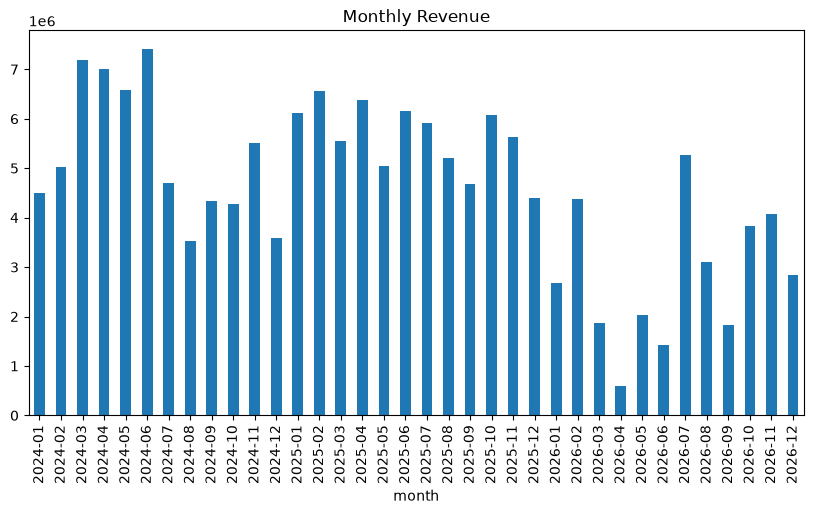

In [25]:
monthly_sales = (
    df.groupby('month')
    ['sale_price_zar']
    .sum()
)

monthly_sales.plot(
    kind='bar',
    figsize=(10,5)
)

plt.title("Monthly Revenue")
plt.show()

**Insight:**

Monthly revenue remained relatively stable throughout the reporting period, although several months, including **July 2024, March 2024, April 2024, May 2024, February 2025 and April 2025.**, generated noticeably higher revenue than the others. Revenue declined significantly during 2026, with **April 2026** recording the lowest revenue in the dataset. This trend may indicate changing market conditions, reduced demand, or incomplete sales activity for later periods and warrants further investigations. 

### 9.2 Top Brands 

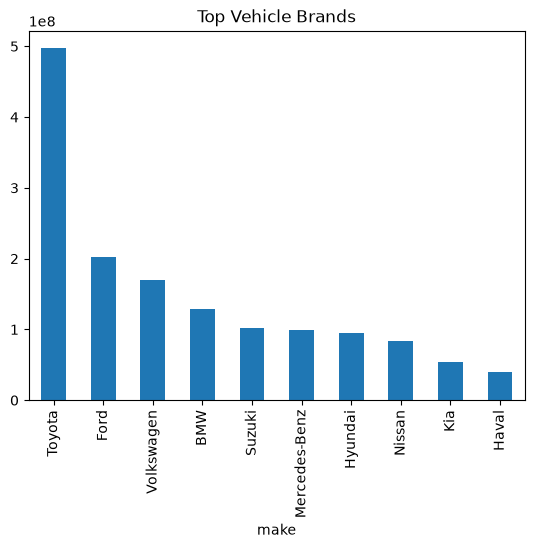

In [26]:
top_brands = (
    df.groupby('make')
    ['sale_price_zar']
    .sum()
    .nlargest(10)
)

top_brands.plot(kind='bar')
plt.title("Top Vehicle Brands")
plt.show()

**Insight:**

**Toyota** generated the highest sales revenue among all vehicle brands, highlighting strong market demand and popularity among customers. **Ford, Volkswagen and BMW** also contributed significantly to overall revenue, suggesting a healthy demand for both mainstream and premium vehicle segments. In contrast, **Haval** generated the lowest revenue, indicating a relatively smaller market share within the dataset. 

### 9.3 Dealer Performance 

<Axes: xlabel='dealer_name'>

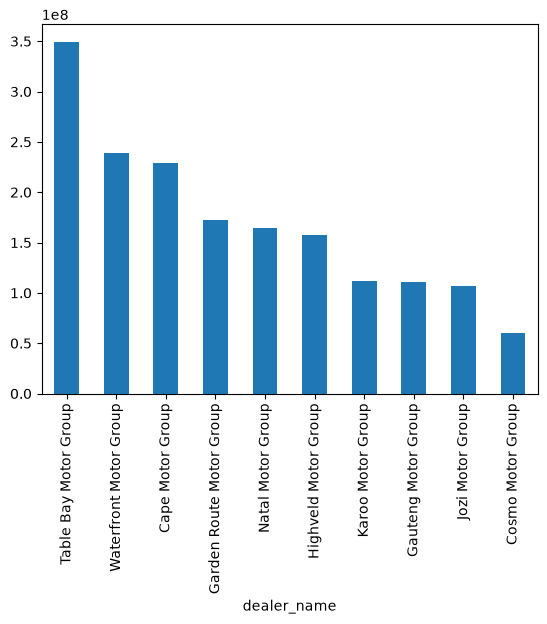

In [27]:
dealer_sales = (
    df.groupby('dealer_name')
    ['sale_price_zar']
    .sum()
)

dealer_sales.sort_values(
    ascending=False
).head(10).plot(kind='bar')

**Insight:**

Dealer performance varies considerably across the network. **Table Bay Motor Group** emerged as the highest-performing dealer, while **Cosmo Motor Group** recorded the lowest revenue contribution. **Waterfront Motor Group and Cape Motor Group** also performed better than the dealers. These results suggest that the best practices from the top-performing dealerships could be analyzed and replicated across lower-performing locations to improve overall sales performance. 

### 9.4 Province Sales 

<Axes: xlabel='province'>

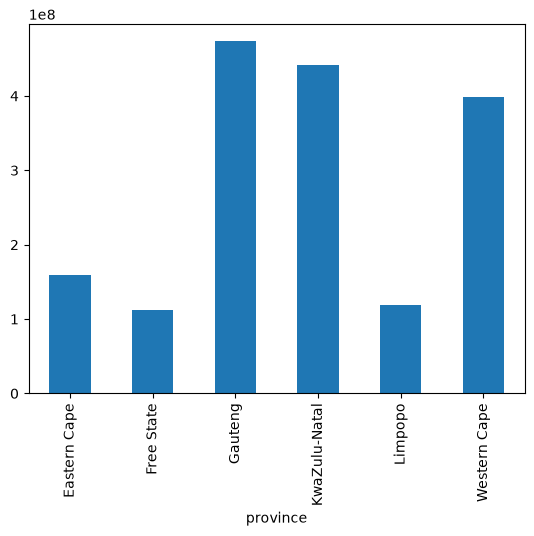

In [28]:
province_sales = (
    df.groupby('province')
    ['sale_price_zar']
    .sum()
)

province_sales.plot(kind='bar')

**Insight:**

**Gauteng** contributed the highest overall revenue, making it the most significant geographic market in the dataset. **Kwazulu-Natal and Western Cape** also contributed better revenue than the other provinces. **Free State** contributed the least revenue in all the provinces. This suggests that vehicle demand is concetrated in a few key provinces, presenting opportunities for targeted marketing and expansion strategies in lower-performing regions. 

## 10. KPI Section 

In [34]:
total_revenue = df['sale_price_zar'].sum()

In [35]:
best_dealer = (
    df.groupby('dealer_name') 
    ['sale_price_zar'] 
    .sum()
    .idxmax()
)

In [36]:
worst_dealer = (
    df.groupby('dealer_name')
    ['sale_price_zar']
    .sum()
    .idxmin()
)

In [37]:
top_brand = (
    df.groupby('make')
    ['sale_price_zar']
    .sum()
    .idxmax()
)

In [38]:
top_province = (
    df.groupby('province')
    ['sale_price_zar']
    .sum()
    .idxmax()
)

## 11. AI Report Prompt 

In [41]:
prompt = f"""
Create a professional vehicle sales report.

Total Revenue:
{total_revenue}

Best Dealer:
{best_dealer} 

Worst Dealer:
{worst_dealer}

Top Brand:
{top_brand}

Top Province:
{top_province}

Include: 
1. Executive Summary 
2. Key Findings 
3. Business Recommendations
"""

print(prompt)


Create a professional vehicle sales report.

Total Revenue:
1736109500

Best Dealer:
Table Bay Motor Group 

Worst Dealer:
Cosmo Motor Group

Top Brand:
Toyota

Top Province:
Gauteng

Include: 
1. Executive Summary 
2. Key Findings 
3. Business Recommendations



## 12. AI Validation Layer 

In [42]:
report = """
Vehicle Sales Performance Report

1. Executive Summary 
Total revenue was R1,736,109,500 (About R1.74 billion). Table Bay Motor Group led the dealers, Cosmo Motor Group trailed, Toyota was the top brand and Gauteng was the top province. 

2. Key Findings 
- Total revenue (R1,736,109,500)
- Best dealer (Table Bay Motor Group) 
- Worst dealer (Cosmo Motor Group) 
- Top brand (Toyota)
- Top province (Gauteng) 

3. Business Recommendations 
- Learn from Table Bay Motor Group and share its sales process across the network. 
- Run a recovery plan for Cosmo Motor Group with clear targets and monthly reviews. 
- Protect and grow the Toyota range through healthy stock and early supply planning.
- Defend Gauteng, and test campaigns in other provinces to reduce reliance on one market. 
- Track results monthly by dealer, brand and province. 
"""

In [44]:
revenue_match = re.search(
    r'R([\d,]+)',
    report
) 

if revenue_match:

    ai_revenue = int( 
        revenue_match.group(1)
        .replace(',', '')
    )

    print("AI Revenue:", ai_revenue) 
    print("Actual Revenue:", total_revenue) 

    if ai_revenue == total_revenue:
        print("Revenue is correct")
    else:
        print("Revenue mismatch")

AI Revenue: 1736109500
Actual Revenue: 1736109500
Revenue is correct


In [45]:
checks = {
    "Best Dealer": best_dealer,
    "Worst Dealer": worst_dealer, 
    "Top Brand": top_brand,
    "Top province": top_province 
}

for kpi, value in checks.items():

    if str(value) in report:
        print(f"{kpi} correct")
    else:
        print(f"{kpi} incorrect")

Best Dealer correct
Worst Dealer correct
Top Brand correct
Top province correct


## 13. AI Validation Results 

The AI-generated report was successfully validated against the calculated business KPIs. 

Validation confirmed:

- Total Revenue
- Best Dealer
- Worst Dealer
- Top Brand
- Top Province

This demonstrates how generative AI can be integrated into reporting workflows while maintaining data accuracy through automated validation checks. 